## Importación módulos de Python y comprobación

In [ ]:
import os
import socket
import sys

print("Equip:", socket.gethostname())
print("Python:", sys.executable)
print("Usuari:", os.getenv("USERNAME") or os.getenv("USER"))

Equip: Portatil-Eme
Python: C:\Users\conta\AppData\Local\Python\pythoncore-3.14-64\python.exe
Usuari: conta


In [ ]:
%pip install sqlalchemy pymysql
%pip install pandas
%pip install matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\conta\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\conta\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\conta\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


## Conexión con MySQL

In [ ]:
import pandas as pd
from sqlalchemy import create_engine

usuario = "root"
contraseña = "emecita"
host = "127.0.0.1"
puerto = "3306" # el puerto de MySQL
base_datos = "user_transactions"

try:
    engine.dispose()
except NameError:
    pass  # si engine no existía aún, no pasa nada

engine = create_engine(f"mysql+pymysql://{usuario}:{contraseña}@{host}:{puerto}/{base_datos}")

df_prueba = pd.read_sql("SELECT * FROM dim_companies", engine)
df_prueba.head(5)


,company_id,company_name,phone,email,country,website
0,b-2222,Ac Fermentum Incorporated,06 85 56 52 33,donec.porttitor.tellus@yahoo.net,Germany,https://instagram.com/site\r
1,b-2226,Magna A Neque Industries,04 14 44 64 62,risus.donec.nibh@icloud.org,Australia,https://whatsapp.com/group/9\r
2,b-2230,Fusce Corp.,08 14 97 58 85,risus@protonmail.edu,United States,https://pinterest.com/sub/cars\r
3,b-2234,Convallis In Incorporated,06 66 57 29 50,mauris.ut@aol.couk,Germany,https://cnn.com/user/110\r
4,b-2238,Ante Iaculis Nec Foundation,08 23 04 99 53,sed.dictum.proin@outlook.ca,New Zealand,https://netflix.com/settings\r


## EJERCICIOS NIVEL 1

### Ejercicio 1: Preguntas analíticas directas

1. ¿Cómo evoluciona el número de transacciones a lo largo del tiempo?

Primero reviso que la variable de fecha tenga el tipo correcto.

In [ ]:
df_transacciones = pd.read_sql("SELECT * FROM fact_transactions", engine)
df_transacciones["transaction_timestamp"].dtype

dtype('<M8[us]')

Creo la columna "year" sacando solamente el año del timestamp.

In [ ]:
df_transacciones["year"] = df_transacciones["transaction_timestamp"].dt.year
df_transacciones[["transaction_timestamp", "year"]].head()

,transaction_timestamp,year
0,2024-08-28 07:16:46,2024
1,2016-12-21 20:07:18,2016
2,2020-07-14 15:37:45,2020
3,2017-09-04 19:44:53,2017
4,2017-01-05 18:19:25,2017


Hago un conteo de las transacciones por año, cuyo resultado genera la series "transacciones_por_año".

In [ ]:
transacciones_por_año = df_transacciones["year"].value_counts()
transacciones_por_año

year
2021    10298
2022    10106
2020    10093
2019    10015
2023     9985
2024     9951
2017     9915
2018     9912
2015     9870
2016     9855
Name: count, dtype: int64

Ordeno las transacciones de menor a mayor (año) con sort_index(), el año es el índice en mi series.

In [ ]:
transacciones_por_año = transacciones_por_año.sort_index()
transacciones_por_año

year
2015     9870
2016     9855
2017     9915
2018     9912
2019    10015
2020    10093
2021    10298
2022    10106
2023     9985
2024     9951
Name: count, dtype: int64

Importo la librería de matplotlib para graficar.

Con .plot hago una gráfica simple de líneas que contiene los datos de mi series "transacciones_por_año". Defino el tamaño, el título de los ejes y de la gráfica en general, y activo el grid para mayor claridad.

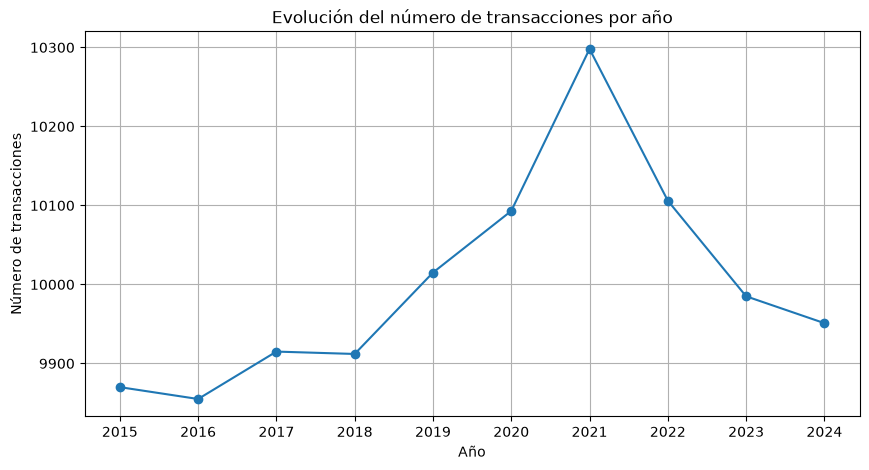

In [ ]:
import matplotlib.pyplot as plt

transacciones_por_año.plot(kind="line", marker="o", figsize=(10, 5))
plt.title("Evolución del número de transacciones por año")
plt.xlabel("Año")
plt.ylabel("Número de transacciones")
plt.xticks(transacciones_por_año.index)
plt.grid(True)
plt.show()

In [ ]:
df_transacciones["transaction_timestamp"].max()

Timestamp('2024-12-31 23:31:55')

La evolución de las transacciones sobre el tiempo es creciente, teniendo un pico en el año 2021 pero luego cae drásticamente en el 2024. Como mi análisis  tomó en cuenta solamente los años, voy a revisar si tengo los meses completos del 2024.

Selecciono la fecha máxima registrada en los datos para ver hasta qué mes llega. Sí hay datos de todo el año, eso signfica que la caída en el 2024 corresponde con los datos registrados.

Las ventas bajaron desde el 2022 y han ido decreciendo, no se han mantenido constantes.

2. ¿Qué usuarios generan mayor volumen de facturación?

Obtengo las transacciones agrupadas por usuario y hago una suma del amount de cada usuario, para sacar el total.

In [ ]:
facturacion_por_usuario = df_transacciones.groupby("user_id")["amount"].sum()
facturacion_por_usuario.head()

user_id
1     8007.43
2     8235.64
3     9078.82
4     7786.63
5    11120.65
Name: amount, dtype: float64

Ordeno la suma de las facturas por usuario de mayor a menor para ver primero quién ha facturado más.

In [ ]:
facturacion_por_usuario = facturacion_por_usuario.sort_values(ascending=False)
facturacion_por_usuario.head()

user_id
289    41486.54
318    40348.50
455    34491.27
417    32016.11
185    30333.03
Name: amount, dtype: float64

"Guardo" los primeros 15 usuarios en top_15_usuarios para trabajarlos después en la visualización.

In [ ]:
top_15_usuarios = facturacion_por_usuario.head(15)
top_15_usuarios

user_id
289    41486.54
318    40348.50
455    34491.27
417    32016.11
185    30333.03
285    29249.51
193    25485.05
454    24353.91
349    23504.47
317    18991.45
388    18923.10
319    17770.39
443    17310.42
393    16726.47
437    16260.46
Name: amount, dtype: float64

Creo un nuevo dataframe a partir de mi series top_15_usuarios ahora con las columnas de "user_id" y "total_facturado" porque seaborn trabaja mejor con dataframes que con series.

In [ ]:
top_15_df = top_15_usuarios.reset_index()
top_15_df.columns = ["user_id", "total_facturado"]
top_15_df

,user_id,total_facturado
0,289,41486.54
1,318,40348.50
2,455,34491.27
3,417,32016.11
4,185,30333.03
5,285,29249.51
6,193,25485.05
7,454,24353.91
8,349,23504.47
9,317,18991.45


In [ ]:
%pip install seaborn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\conta\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


Importo seaborn y creo una lista llamada "colores" que asigna el color "purple" a las primeras 5 barras y azul a las restantes (calcula el resto midiendo la cantidad de filas [len] del df, restando las primeras 5). Le paso esta lista al parámetro "palette" del barplot.

C:\Users\conta\AppData\Local\Temp\ipykernel_8356\2820242844.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_15_df, x="total_facturado", y="user_id", order=top_15_df["user_id"], orient="h", palette=colores)


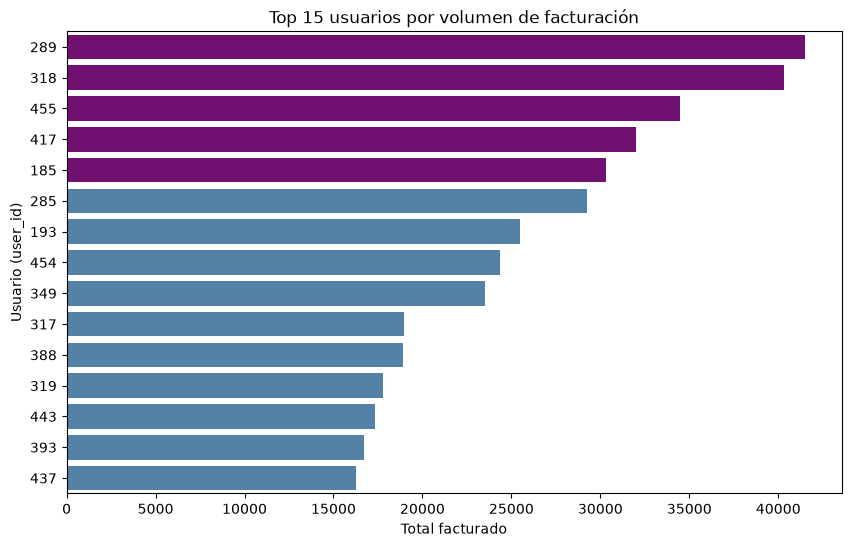

In [ ]:
import seaborn as sns

colores = ["purple"] * 5 + ["steelblue"] * (len(top_15_df) - 5)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_15_df, x="total_facturado", y="user_id", order=top_15_df["user_id"], orient="h", palette=colores)
plt.title("Top 15 usuarios por volumen de facturación")
plt.xlabel("Total facturado")
plt.ylabel("Usuario (user_id)")
plt.show()

CONLCUSIONES

Podemos ver que los primeros 2 usuarios facturan cantidades significativamente mayores que el resto. Y esos primeros 5 usuario facturan casi el doble o más que el usuario de id 437, el que menos factura de ese top 15. Sería interesante hacer más análisis de distribución incluyendo a todos los usuarios que facturan para entender mejor sus comportamientos.

A continuación hago un merge para obtener más información de ese top 15 de usuarios que más facturan. Todos pertenecen a Europa o UK. Polonia aparece más veces (3). Aunque más adelante veremos que Polonia no figura entre los países que más facturan, a nivel global.

In [ ]:
df_users = pd.read_sql("SELECT * FROM dim_users", engine)
top_15_df = top_15_df.merge(df_users[["user_id", "name", "surname", "country"]], on="user_id", how="left")
top_15_df

,user_id,total_facturado,name,surname,country
0,289,41486.54,Dxwgi,Hwcru,Germany
1,318,40348.50,Bnyr,Astuw,Italy
2,455,34491.27,Fwfll,Phylgnmhnd,Poland
3,417,32016.11,Fqatil,Rdwcjcvoa,Portugal
4,185,30333.03,Molly,Gilliam,United Kingdom
5,285,29249.51,Brcxprnj,Lnpna,Spain
6,193,25485.05,Minerva,Wilkins,United Kingdom
7,454,24353.91,Sfzzoh,Xgvfridxs,Poland
8,349,23504.47,Yxxcjk,Fnceqbkxmt,Sweden
9,317,18991.45,Qikcvc,Nvfcifqdh,Poland


3. ¿Existen diferencias en la distribución del importe de las transacciones según la hora del día y si han sido aceptadas o rechazadas?



Obtengo únicamente la hora del transaction timestamp y le llamo "hora" a esa series.

In [ ]:
df_transacciones["hora"] = df_transacciones["transaction_timestamp"].dt.hour
df_transacciones[["transaction_timestamp", "hora"]].head()

,transaction_timestamp,hora
0,2024-08-28 07:16:46,7
1,2016-12-21 20:07:18,20
2,2020-07-14 15:37:45,15
3,2017-09-04 19:44:53,19
4,2017-01-05 18:19:25,18


Creo una nueva columna para el df_transacciones ("estado") que contiene los valores de "declined" mapeados con un diccionario de referencia para que mi columna nueva diga "Aceptada" o "Rechazada" según el valor del booleano.

In [ ]:
df_transacciones["estado"] = df_transacciones["declined"].map({0: "Aceptada", 1: "Rechazada"})
df_transacciones[["declined", "estado"]].head()

,declined,estado
0,0,Aceptada
1,0,Aceptada
2,0,Aceptada
3,0,Aceptada
4,0,Aceptada


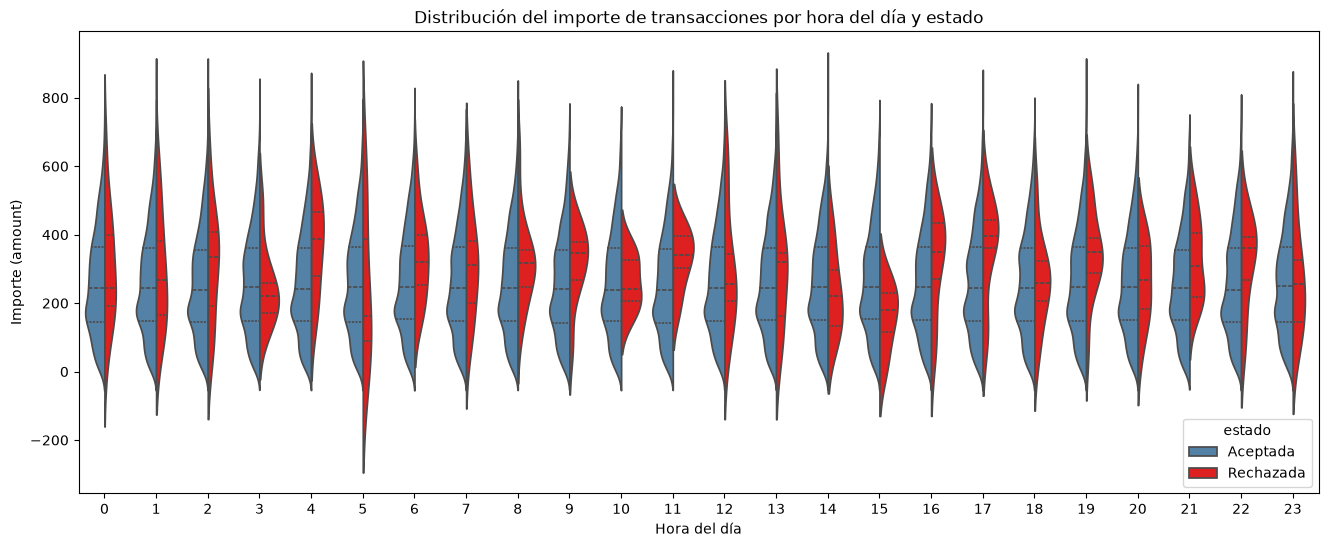

In [ ]:
plt.figure(figsize=(16, 6))
colores_estado = {"Aceptada": "steelblue", "Rechazada": "red"}
sns.violinplot(data=df_transacciones, x="hora", y="amount", hue="estado", split=True, inner="quartile", palette=colores_estado)
plt.title("Distribución del importe de transacciones por hora del día y estado")
plt.xlabel("Hora del día")
plt.ylabel("Importe (amount)")
plt.show()

CONCLUSIONES

La gran mayoría de las transacciones se concentran entre los ~150/450 euros de importe. Son minoría las que pasan de 600€.
Las transacciones aceptadas son muchas más que las rechazadas.
La distribución está bien repartida entre las 24 horas del día, teniendo solo un pico a las 5 horas.


4. ¿En qué días de la semana se concentra mayor actividad de venta?

In [ ]:
dias_es = {
    0: "Lunes",
    1: "Martes",
    2: "Miércoles",
    3: "Jueves",
    4: "Viernes",
    5: "Sábado",
    6: "Domingo"
}

df_transacciones["dia_semana"] = df_transacciones["transaction_timestamp"].dt.dayofweek.map(dias_es)
facturacion_por_dia = df_transacciones.groupby("dia_semana")["amount"].sum()
facturacion_por_dia

dia_semana
Domingo      3708031.17
Jueves       3732422.09
Lunes        3623384.50
Martes       3702410.86
Miércoles    3684742.75
Sábado       3730011.72
Viernes      3720528.08
Name: amount, dtype: float64

In [ ]:
from pandas.api.types import CategoricalDtype

orden_dias = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
cat_dias = CategoricalDtype(categories=orden_dias, ordered=True)

df_transacciones["dia_semana"] = df_transacciones["dia_semana"].astype(cat_dias)
df_transacciones["dia_semana"].dtype

CategoricalDtype(categories=['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes',
                  'Sábado', 'Domingo'],
, ordered=True, categories_dtype=str)

Una vez definida mi columna "dia_semana" y ya en el orden correcto de los días de la semana, calculo la suma del amount por día de la semana:

In [ ]:
facturacion_por_dia = df_transacciones.groupby("dia_semana")["amount"].sum()
facturacion_por_dia

dia_semana
Lunes        3623384.50
Martes       3702410.86
Miércoles    3684742.75
Jueves       3732422.09
Viernes      3720528.08
Sábado       3730011.72
Domingo      3708031.17
Name: amount, dtype: float64

In [ ]:
facturacion_por_dia_df = facturacion_por_dia.reset_index()
facturacion_por_dia_df.columns = ["dia_semana", "total_facturado"]
facturacion_por_dia_df.sort_values("total_facturado", ascending=False)

,dia_semana,total_facturado
3,Jueves,3732422.09
5,Sábado,3730011.72
4,Viernes,3720528.08
6,Domingo,3708031.17
1,Martes,3702410.86
2,Miércoles,3684742.75
0,Lunes,3623384.50


Identificamos los 3 días con mayor facturación:

C:\Users\conta\AppData\Local\Temp\ipykernel_8356\2985005477.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=facturacion_por_dia_df, x="dia_semana", y="total_facturado", palette=colores)


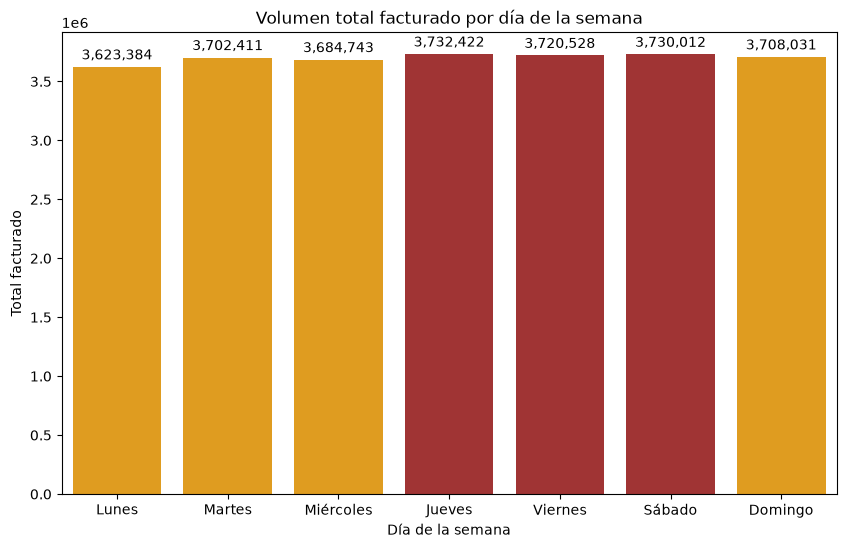

In [ ]:
colores = ["orange"] * len(facturacion_por_dia_df)
top_3_idx = facturacion_por_dia_df["total_facturado"].nlargest(3).index
for idx in top_3_idx:
    colores[idx] = "firebrick"

plt.figure(figsize=(10, 6))
ax = sns.barplot(data=facturacion_por_dia_df, x="dia_semana", y="total_facturado", palette=colores)
for contenedor in ax.containers:
    ax.bar_label(contenedor, labels=[f"{v:,.0f}" for v in contenedor.datavalues], padding=3)
plt.title("Volumen total facturado por día de la semana")
plt.xlabel("Día de la semana")
plt.ylabel("Total facturado")
plt.show()

Aunque en todos los días de la semana se facturan cantidades más o menos similares, los días que más facturan son los jueves, sábado y viernes, justo en ese orden. Esto podría indicar que la cantidad de ventas se mantiene bastante constante a lo largo de la semana. Habría que analizar por país o por compañía para ver si las cantidades siguen igual de distribuidas, pero a nivel general incluyendo todas las transacciones, se venden más de 3,600,000 euros todos los días.

### Ejercicio 2: Preguntas analíticas complejas.

1. ¿Dependemos excesivamente de un número reducido de países de compañías vendedoras?

Pasos orientativos:

- Combinar la información de transacciones con la de compañías.

- Agrupar la facturación por país.

- Calcular la facturación total generada por cada país.

- Ordenar los países de mayor a menor facturación.

- Calcular el porcentaje acumulado sobre el total.

- Visualizar.

In [ ]:
df_companies = pd.read_sql("SELECT company_id, company_name, country FROM dim_companies", engine)
df_transacciones = df_transacciones.merge(df_companies, on="company_id", how="left")
df_transacciones[["company_id", "company_name", "country"]].head(20)

,company_id,company_name,country
0,b-2458,Eget Tincidunt Dui Institute,Netherlands
1,b-2370,Non Justo Corp.,Sweden
2,b-2390,Neque Tellus Imperdiet Corp.,Ireland
3,b-2230,Fusce Corp.,United States
4,b-2266,Mus Aenean Eget Foundation,Sweden
5,b-2598,Aliquam Iaculis Lacus Corp.,Belgium
6,b-2546,Lorem Ipsum Dolor Corp.,Sweden
7,b-2526,Amet Luctus Vulputate Foundation,Canada
8,b-2558,Nulla Integer Vulputate Corp.,Sweden
9,b-2550,Auctor Mauris Corp.,Germany


In [ ]:
facturacion_por_pais = df_transacciones.groupby("country")["amount"].sum()
facturacion_por_pais.sort_values(ascending=False)

country
Sweden            4251072.86
Netherlands       3890755.90
United Kingdom    3537120.34
Italy             3530071.81
Germany           3466842.93
France            1221902.17
United States     1069450.71
Belgium            922131.39
Norway             785907.27
Ireland            693054.42
New Zealand        685567.09
Australia          679418.68
Canada             542407.60
Spain              394609.21
China              231218.79
Name: amount, dtype: float64

In [ ]:
porcentaje_por_pais = facturacion_por_pais / facturacion_por_pais.sum() * 100
porcentaje_acumulado = porcentaje_por_pais.cumsum()

resumen_paises = pd.DataFrame({
    "facturacion_total": facturacion_por_pais,
    "porcentaje": porcentaje_por_pais,
    "porcentaje_acumulado": porcentaje_acumulado
})

resumen_paises = resumen_paises.sort_values("facturacion_total", ascending=False)
resumen_paises["porcentaje_acumulado"] = resumen_paises["porcentaje"].cumsum()
resumen_paises

,facturacion_total,porcentaje,porcentaje_acumulado
country,,,
Sweden,4251072.86,16.412438,16.412438
Netherlands,3890755.90,15.021336,31.433774
United Kingdom,3537120.34,13.656028,45.089802
Italy,3530071.81,13.628815,58.718617
Germany,3466842.93,13.384703,72.103320
France,1221902.17,4.717490,76.820810
United States,1069450.71,4.128909,80.949719
Belgium,922131.39,3.560142,84.509861
Norway,785907.27,3.034212,87.544073


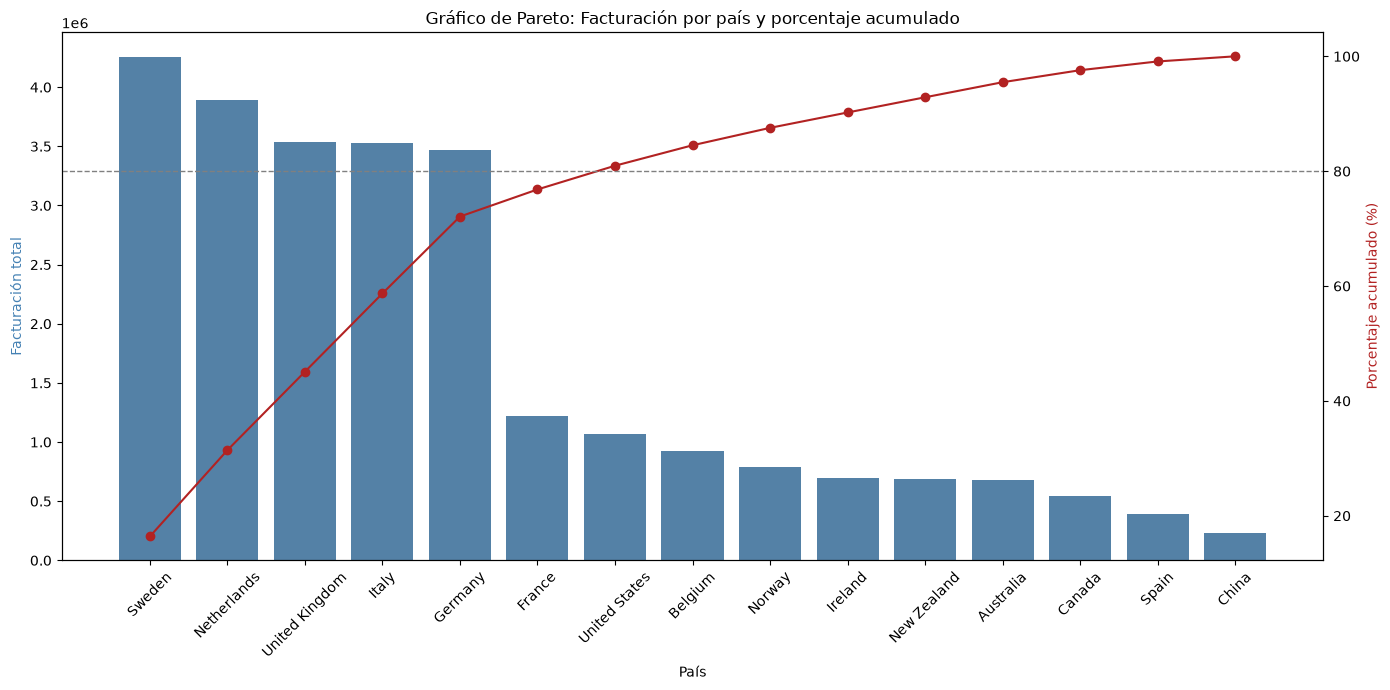

In [ ]:
resumen_paises_plot = resumen_paises.reset_index()

fig, ax1 = plt.subplots(figsize=(14, 7))

sns.barplot(data=resumen_paises_plot, x="country", y="facturacion_total", color="steelblue", ax=ax1)
ax1.set_xlabel("País")
ax1.set_ylabel("Facturación total", color="steelblue")
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.plot(resumen_paises_plot["country"], resumen_paises_plot["porcentaje_acumulado"], color="firebrick", marker="o")
ax2.set_ylabel("Porcentaje acumulado (%)", color="firebrick")
ax2.axhline(80, color="gray", linestyle="--", linewidth=1)

plt.title("Gráfico de Pareto: Facturación por país y porcentaje acumulado")
fig.tight_layout()
plt.show()

INSIGHTS:

*Solo 4 países (Suecia, Países Bajos, Reino Unido, Italia) ya concentran cerca del 58.7% de toda la facturación. Si sumamos Alemania, llegamos al 72.1%*

*En el otro extremo, los últimos 4-5 países (Nueva Zelanda, Australia, Canadá, España, China) apenas suman entre todos alrededor del 10% del total.*

*Esto sí es una señal bastante clara de concentración: con menos de un tercio de los países (5 de 15), ya tenemos más del 70% de la facturación.*

2. ¿Existe estacionalidad en las ventas?
Pasos orientativos:

Trabajar con fechas de transacción.
- Extraer la información temporal relevante (año y mes).
- Calcular el volumen total de ventas (suma de amount) por año y mes.
-  Comparar patrones temporales con la comparación entre años. Crea una mesa tipo pívot.
- Visualizar la evolución

In [ ]:
df_transacciones["month"] = df_transacciones["transaction_timestamp"].dt.month

meses_es = {
    1: "Enero", 2: "Febrero", 3: "Marzo", 4: "Abril",
    5: "Mayo", 6: "Junio", 7: "Julio", 8: "Agosto",
    9: "Septiembre", 10: "Octubre", 11: "Noviembre", 12: "Diciembre"
}

df_transacciones["month_name"] = df_transacciones["month"].map(meses_es)
df_transacciones[["transaction_timestamp", "year", "month", "month_name"]].head()

,transaction_timestamp,year,month,month_name
0,2024-08-28 07:16:46,2024,8,Agosto
1,2016-12-21 20:07:18,2016,12,Diciembre
2,2020-07-14 15:37:45,2020,7,Julio
3,2017-09-04 19:44:53,2017,9,Septiembre
4,2017-01-05 18:19:25,2017,1,Enero


In [ ]:
ventas_por_año_mes = df_transacciones.groupby(["year", "month"])["amount"].sum()
ventas_por_año_mes

year  month
2015  1        208460.24
      2        211179.56
      3        221488.19
      4        214675.51
      5        215691.13
                 ...    
2024  8        214924.40
      9        212523.25
      10       217337.57
      11       212989.12
      12       229226.98
Name: amount, Length: 120, dtype: float64

In [ ]:
tabla_pivote = df_transacciones.pivot_table(
    index="year",
    columns="month",
    values="amount",
    aggfunc="sum"
)
tabla_pivote

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2015,208460.24,211179.56,221488.19,214675.51,215691.13,207759.31,218137.92,214170.06,204305.09,207329.31,206086.20,215907.55
2016,212357.82,214708.37,215368.86,210019.54,208713.77,208534.96,213505.12,212853.75,217441.50,213392.79,212567.32,216880.92
2017,209339.50,215198.48,208608.27,218995.78,204784.10,216287.92,218788.44,209566.97,211802.81,207924.36,219837.77,230320.82
2018,214646.54,209918.88,207377.32,205562.05,210126.23,217047.48,208823.33,207536.16,214016.87,219609.95,218591.71,213640.31
2019,210813.99,222423.06,243592.36,212679.25,208853.84,220443.02,211037.50,215470.42,210429.63,213913.65,209583.99,231577.72
2020,219397.63,211273.68,227262.89,213422.08,216073.84,212762.98,217751.47,210762.54,231158.60,221645.25,201522.40,224453.23
2021,232197.63,219685.97,220554.92,227276.44,206925.66,211362.56,227301.53,214414.67,222361.90,227128.13,217622.12,222631.39
2022,212873.78,202945.83,238293.06,209160.91,236573.86,233213.16,211532.08,220744.50,228802.26,218577.07,210127.87,217191.26
2023,218300.84,214480.16,212086.80,214159.74,225828.47,210788.42,215904.46,214257.04,213400.04,213194.28,212763.80,215360.53


In [ ]:
from pandas.api.types import CategoricalDtype

orden_meses = ["Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio",
               "Julio", "Agosto", "Septiembre", "Octubre", "Noviembre", "Diciembre"]
cat_meses = CategoricalDtype(categories=orden_meses, ordered=True)

df_transacciones["month_name"] = df_transacciones["month_name"].astype(cat_meses)

tabla_pivote = df_transacciones.pivot_table(
    index="year",
    columns="month_name",
    values="amount",
    aggfunc="sum"
)
tabla_pivote

month_name,Enero,Febrero,Marzo,Abril,Mayo,Junio,Julio,Agosto,Septiembre,Octubre,Noviembre,Diciembre
year,,,,,,,,,,,,
2015,208460.24,211179.56,221488.19,214675.51,215691.13,207759.31,218137.92,214170.06,204305.09,207329.31,206086.20,215907.55
2016,212357.82,214708.37,215368.86,210019.54,208713.77,208534.96,213505.12,212853.75,217441.50,213392.79,212567.32,216880.92
2017,209339.50,215198.48,208608.27,218995.78,204784.10,216287.92,218788.44,209566.97,211802.81,207924.36,219837.77,230320.82
2018,214646.54,209918.88,207377.32,205562.05,210126.23,217047.48,208823.33,207536.16,214016.87,219609.95,218591.71,213640.31
2019,210813.99,222423.06,243592.36,212679.25,208853.84,220443.02,211037.50,215470.42,210429.63,213913.65,209583.99,231577.72
2020,219397.63,211273.68,227262.89,213422.08,216073.84,212762.98,217751.47,210762.54,231158.60,221645.25,201522.40,224453.23
2021,232197.63,219685.97,220554.92,227276.44,206925.66,211362.56,227301.53,214414.67,222361.90,227128.13,217622.12,222631.39
2022,212873.78,202945.83,238293.06,209160.91,236573.86,233213.16,211532.08,220744.50,228802.26,218577.07,210127.87,217191.26
2023,218300.84,214480.16,212086.80,214159.74,225828.47,210788.42,215904.46,214257.04,213400.04,213194.28,212763.80,215360.53


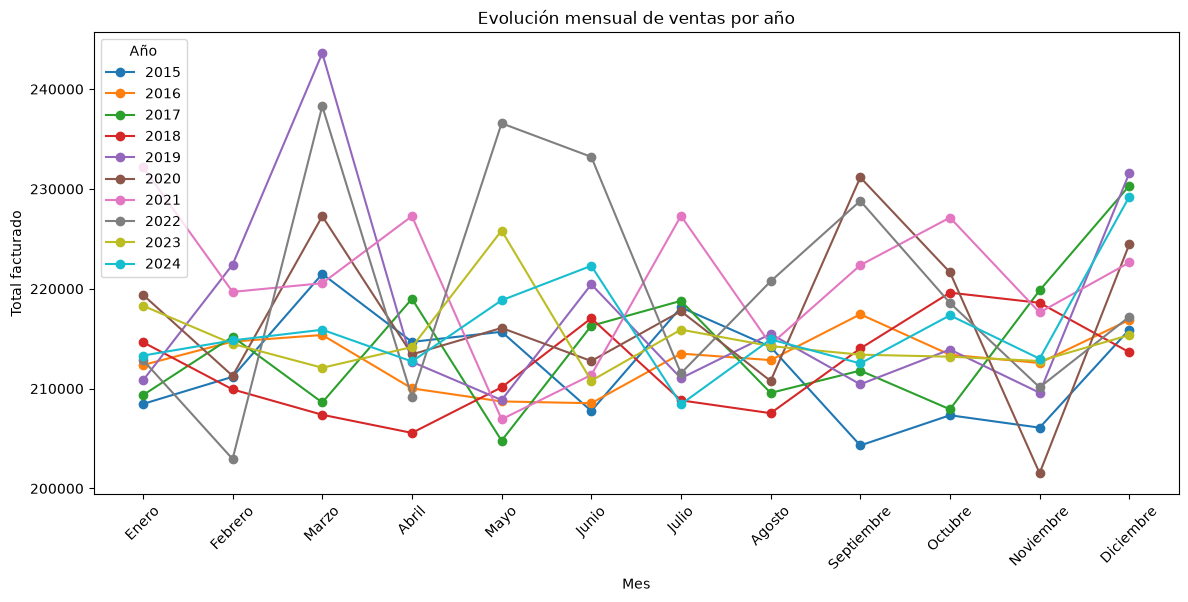

In [ ]:
plt.figure(figsize=(14, 6))
for año in tabla_pivote.index:
    plt.plot(tabla_pivote.columns, tabla_pivote.loc[año], marker="o", label=año)

plt.title("Evolución mensual de ventas por año")
plt.xlabel("Mes")
plt.ylabel("Total facturado")
plt.xticks(rotation=45)
plt.legend(title="Año")
plt.show()

Con este gráfico de líneas podemos ver más visualmente todas las fluctuaciones de cada año por mes. Los años que más resaltan visualmente son el 2019, por ejemplo, que tiene un punto muy alto en el mes de marzo facturando más de 240,000.

También llama la atención el año 2022 porque en febrero estuvo muy bajo y luego subió hasta casi 240,000 facturados, volviendo a bajar en abril y subiendo en mayo y junio.

Los años menos fluctuantes fueron el 2016, el 2024 quizás, el 2017...

Este tipo de gráfico deja ver muy claramente los distintos movimientos de cada año e identificar coincidencias, por ejemplo, marzo ha sido un mes de crecimiento para varios años. Abril al contrario.

3. ¿Hay usuarios que han dejado de comprar recientemente?

Pasos orientativos:

- Identificar la última compra por usuario.

- Calcular el tiempo desde la última compra.

- Visualizar la distribución del tiempo desde la última compra.

In [ ]:
ultima_compra_usuario = df_transacciones.groupby("user_id")["transaction_timestamp"].max()
ultima_compra_usuario.head()

user_id
1   2024-11-15 14:48:20
2   2024-04-20 06:41:27
3   2024-02-22 03:31:36
4   2024-12-29 11:47:48
5   2024-05-02 21:11:06
Name: transaction_timestamp, dtype: datetime64[us]

In [ ]:
fecha_referencia = df_transacciones["transaction_timestamp"].max()
dias_desde_ultima_compra = (fecha_referencia - ultima_compra_usuario).dt.days
dias_desde_ultima_compra.head()

user_id
1     46
2    255
3    313
4      2
5    243
Name: transaction_timestamp, dtype: int64

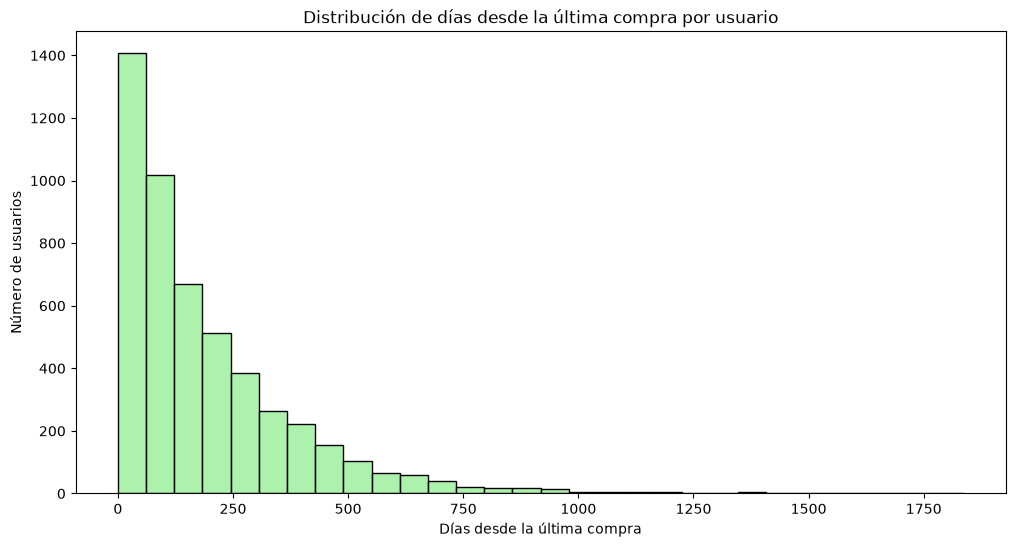

In [ ]:
plt.figure(figsize=(12, 6))
sns.histplot(dias_desde_ultima_compra, bins=30, color="lightgreen")
plt.title("Distribución de días desde la última compra por usuario")
plt.xlabel("Días desde la última compra")
plt.ylabel("Número de usuarios")
plt.show()

Este gráfico nos permite visualizar el tiempo transcurrido desde la última compra de los usuarios. Vemos que la barra más alta representa que 1400 usuarios llevan entre 0-60 días desde la última vez que compraron.

Vemos también que menos de 200 usuarios llevan más de 500 días (más o menos año y medio) desde la última vez que compraron. Y probablemente menos de 25 usuarios llevan 750 días o más sin comprar otra vez. Realmente muy pocos.

La mayoría de los usuarios se encuentran en el rango de 0 a 250 días sin comprar de nuevo. Dependiendo del negocio, esto podría indicar que el primer año después de comprar es clave para crear "re-engagement" a los usuarios.

4.  ¿Cómo varía la actividad de venta por franjas horarias a lo largo de los años? (patrones horarios)

Pasos orientativos:

- Crear franjas horarias a partir de la hora: crea una función y aplícala utilizando apply.

- Construir una tabla agregada utilizando crosstab.

- Visualizar con un heatmap.

In [ ]:
def asignar_franja(hora):
    if 0 <= hora < 6:
        return "Madrugada"
    elif 6 <= hora < 12:
        return "Mañana"
    elif 12 <= hora < 18:
        return "Tarde"
    else:
        return "Noche"

df_transacciones["franja_horaria"] = df_transacciones["hora"].apply(asignar_franja)
df_transacciones[["hora", "franja_horaria"]].head()

,hora,franja_horaria
0,7,Mañana
1,20,Noche
2,15,Tarde
3,19,Noche
4,18,Noche


In [ ]:
tabla_franjas = pd.crosstab(index=df_transacciones["year"], columns=df_transacciones["franja_horaria"], values=df_transacciones["amount"], aggfunc="sum")
tabla_franjas

franja_horaria,Madrugada,Mañana,Noche,Tarde
year,,,,
2015,634217.00,631480.53,638291.26,641201.28
2016,637156.46,646776.32,614261.05,658150.89
2017,629540.64,638536.96,631846.36,671531.26
2018,649588.10,616194.09,639559.01,641555.63
2019,634341.30,665608.61,646851.09,664017.43
2020,669367.83,648667.63,657116.82,632334.31
2021,662185.11,670951.45,643993.22,672333.14
2022,665762.40,636430.72,675974.25,661868.27
2023,664766.21,645600.52,621165.03,648992.82


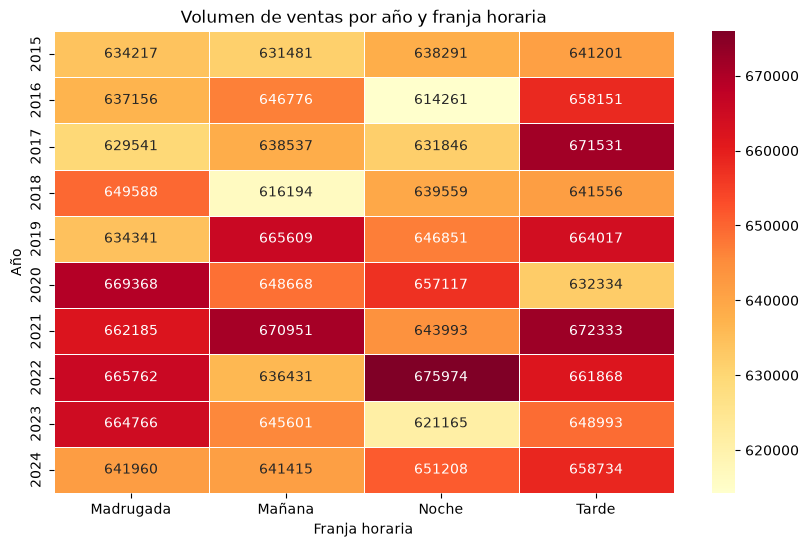

In [ ]:
plt.figure(figsize=(10, 6))
sns.heatmap(tabla_franjas, cmap="YlOrRd", annot=True, fmt=".0f", linewidths=0.5)
plt.title("Volumen de ventas por año y franja horaria")
plt.xlabel("Franja horaria")
plt.ylabel("Año")
plt.show()

Consideré que un heatmap representaría mejor en qué momentos del día se factura más o menos.

Es interesante ver que la tarde registra "más rojos", es decir, los mayores importes. Y las mañanas tienen más "amarillos", importes un tanto menores.

2022 y 2021 registraron mayores importes (3 rojos), mientras que el 2015 y 2018 no tuvieron más de 649,588 en facturación, estuvieron un poco más bajos.

## EJERCICIOS NIVEL 2

### Ejercicio 2: Análisis geográfico compañía-usuario y oportunidades de expansión

**Objetivo:**

 Analizar la relación entre el país de las compañías vendedoras, el país de residencia de los usuarios y el flujo de compra entre países.

¿El negocio está basado en mercados locales (mismo país usuario-compañía) o hay una oportunidad real de expansión internacional abriendo más compañías en ciertos países?

**Pasos orientativos:**

1. Analiza el comportamiento global:

  - Porcentaje de transacciones locales vs internacionales.
  - Porcentaje de facturación local vs internacional.

**Paso 1:** Para saber si una compra fue "local" necesitamos el país del usuario y el país de la compañía en la misma fila, así que hago un merge entre la tabla de dimensión usuarios y la tabla transacciones.

Renombro la columna país para evitar conflictos porque ambas tablas la llaman igual.

Hago dos merge consecutivos: primero traigo el país del usuario (por user_id), y sobre ese resultado, hago un segundo merge para traer el país de la compañía (por company_id).

In [ ]:
df_usuarios_pais = pd.read_sql("SELECT user_id, country FROM dim_users", engine)

df_analisis = df_transacciones.merge(
    df_usuarios_pais.rename(columns={"country": "pais_usuario"}),
    on="user_id",
    how="left"
)

df_analisis = df_analisis.merge(
    df_companies.rename(columns={"country": "pais_compania"}),
    on="company_id",
    how="left"
)

df_analisis[["user_id", "pais_usuario", "company_id", "pais_compania", "amount"]].head()

,user_id,pais_usuario,company_id,pais_compania,amount
0,4713,France,b-2458,Netherlands,395.43
1,438,Italy,b-2370,Sweden,155.63
2,2118,United States,b-2390,Ireland,326.01
3,2115,Canada,b-2230,United States,161.60
4,3025,Netherlands,b-2266,Sweden,148.91


In [ ]:
df_analisis["compra_local"] = df_analisis["pais_usuario"] == df_analisis["pais_compania"]
df_analisis[["pais_usuario", "pais_compania", "compra_local"]].head(10)

,pais_usuario,pais_compania,compra_local
0,France,Netherlands,False
1,Italy,Sweden,False
2,United States,Ireland,False
3,Canada,United States,False
4,Netherlands,Sweden,False
5,Canada,Belgium,False
6,Netherlands,Sweden,False
7,Canada,Canada,True
8,United Kingdom,Sweden,False
9,Netherlands,Germany,False


In [ ]:
conteo_local = df_analisis["compra_local"].value_counts()
porcentaje_transacciones = conteo_local / conteo_local.sum() * 100

facturacion_local = df_analisis.groupby("compra_local")["amount"].sum()
porcentaje_facturacion = facturacion_local / facturacion_local.sum() * 100

resumen_global = pd.DataFrame({
    "porcentaje_transacciones": porcentaje_transacciones,
    "porcentaje_facturacion": porcentaje_facturacion
})
resumen_global

,porcentaje_transacciones,porcentaje_facturacion
compra_local,,
False,88.138,88.040985
True,11.862,11.959015


Lo que dicen estos números:

*False* (compras internacionales): 88.1% de las transacciones, 88.0% de la facturación.

*True* (compras locales): solo 11.9% de las transacciones y facturación.
Dos hallazgos importantes aquí:

* El negocio es mayormente internacional, no local. Casi 9 de cada 10 transacciones ocurren entre un usuario y una compañía de países distintos. Esto responde a la primera parte de la pregunta del ejercicio: claramente no es un negocio basado en mercados locales.

* Los porcentajes de transacciones y facturación son casi idénticos (88.1% vs 88.0%, 11.9% vs 12.0%). Esto significa que no hay una diferencia notable en el tamaño promedio del ticket entre compras locales e internacionales. Ambos tipos de transacción tienen, en promedio, montos similares.

2. Análisis por país del usuario, por cada país de usuario:
  - % de compras en compañías del mismo país.
  - % de compras en compañías extranjeras.
  - Importe total comprado.

**Paso 2:** Aquí queremos, para cada país de usuario: % de compras locales, % de compras internacionales, y el importe total comprado.
Primero calculo el importe total comprado por país de usuario:

In [ ]:
importe_por_pais_usuario = df_analisis.groupby("pais_usuario")["amount"].sum()
importe_por_pais_usuario

pais_usuario
Canada            2584178.24
France            2175321.38
Germany           2265471.24
Italy             2238008.35
Netherlands       2316227.02
Poland            2141757.73
Portugal          2250608.19
Spain             2336623.33
Sweden            2089941.13
United Kingdom    2478416.85
United States     3024977.71
Name: amount, dtype: float64

Ahora calculamos el % de compras locales por país de usuario

Como compra_local es una columna de True/False, se puede usar (.mean()) de una columna booleana y pandas trata True como 1 y False como 0, de manera que el promedio da directamente el porcentaje de True (en decimal).

In [ ]:
porcentaje_local_por_pais = df_analisis.groupby("pais_usuario")["compra_local"].mean() * 100
porcentaje_local_por_pais

resumen_pais_usuario = pd.DataFrame({
    "importe_total": importe_por_pais_usuario,
    "pct_local": porcentaje_local_por_pais
})
resumen_pais_usuario["pct_internacional"] = 100 - resumen_pais_usuario["pct_local"]
resumen_pais_usuario = resumen_pais_usuario.sort_values("importe_total", ascending=False)
resumen_pais_usuario

,importe_total,pct_local,pct_internacional
pais_usuario,,,
United States,3024977.71,18.536882,81.463118
Canada,2584178.24,9.713599,90.286401
United Kingdom,2478416.85,17.290349,82.709651
Spain,2336623.33,1.741071,98.258929
Netherlands,2316227.02,19.317041,80.682959
Germany,2265471.24,16.943712,83.056288
Portugal,2250608.19,0.000000,100.000000
Italy,2238008.35,17.102498,82.897502
France,2175321.38,6.277921,93.722079


In [ ]:
resumen_pais_usuario.sort_values("pct_local")

,importe_total,pct_local,pct_internacional
pais_usuario,,,
Portugal,2250608.19,0.000000,100.000000
Poland,2141757.73,0.000000,100.000000
Spain,2336623.33,1.741071,98.258929
France,2175321.38,6.277921,93.722079
Canada,2584178.24,9.713599,90.286401
Germany,2265471.24,16.943712,83.056288
Italy,2238008.35,17.102498,82.897502
United Kingdom,2478416.85,17.290349,82.709651
United States,3024977.71,18.536882,81.463118


3. Análisis por país de compañía, por cada país de compañía calcula qué parte de su facturación viene de:
  - Usuarios locales.
  - Usuarios extranjeros.

**Paso 3:** Ahora el análisis por país de compañía:

De toda la facturación que genera este país de compañías, ¿qué porcentaje viene de usuarios del mismo país vs de afuera?

In [ ]:
importe_por_pais_compania = df_analisis.groupby("pais_compania")["amount"].sum()
porcentaje_local_por_compania = df_analisis.groupby("pais_compania")["compra_local"].mean() * 100

resumen_pais_compania = pd.DataFrame({
    "importe_total": importe_por_pais_compania,
    "pct_usuarios_locales": porcentaje_local_por_compania
})
resumen_pais_compania["pct_usuarios_extranjeros"] = 100 - resumen_pais_compania["pct_usuarios_locales"]
resumen_pais_compania = resumen_pais_compania.sort_values("importe_total", ascending=False)
resumen_pais_compania

,importe_total,pct_usuarios_locales,pct_usuarios_extranjeros
pais_compania,,,
Sweden,4251072.86,10.470538,89.529462
Netherlands,3890755.90,11.497841,88.502159
United Kingdom,3537120.34,12.108014,87.891986
Italy,3530071.81,10.718466,89.281534
Germany,3466842.93,11.120307,88.879693
France,1221902.17,11.361702,88.638298
United States,1069450.71,52.799802,47.200198
Belgium,922131.39,0.000000,100.000000
Norway,785907.27,0.000000,100.000000


**Paso 4:** Grafico un scatterplot.

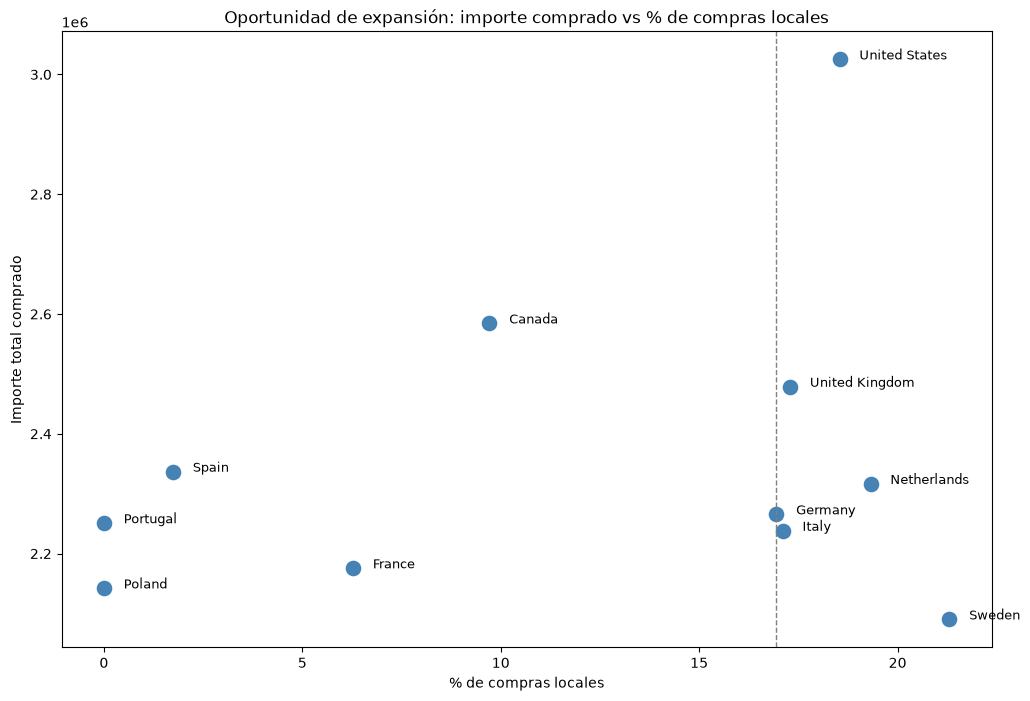

In [ ]:
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=resumen_pais_usuario.reset_index(),
    x="pct_local",
    y="importe_total",
    s=150,
    color="steelblue"
)

for _, fila in resumen_pais_usuario.reset_index().iterrows():
    plt.text(fila["pct_local"] + 0.5, fila["importe_total"], fila["pais_usuario"], fontsize=9)

plt.title("Oportunidad de expansión: importe comprado vs % de compras locales")
plt.xlabel("% de compras locales")
plt.ylabel("Importe total comprado")
plt.axvline(resumen_pais_usuario["pct_local"].median(), color="gray", linestyle="--", linewidth=1)
plt.show()

**Conclusiones**

España, Portugal y Polonia destacan por tener nula o muy poca presencia de compañías locales. Sus usuarios compran casi exclusivamente en el extranjero. Su importe total representa un volumen de negocio considerable y el hecho de que su pct_local sea alrededor del 0% sugiere que puede que no exista ninguna compañía en esos países aún.

Suecia y Holanda tienen más cobertura local. Interesante notar que Suecia, a pesar de tener el pct_local más alto de la lista, tiene el importe total más bajo del grupo. Sería interesante investigar por qué...

**1. ¿En qué países valdría la pena abrir más compañías locales?**

Según la tabla final, los candidatos más claros son los que combinan alto importe comprado con baja o nula oferta local.

Portugal y Polonia - 0 compañías, pero con aprox. 2.1-2.25M en compras. Son los casos más claros: hay demanda real y sustancial, sin ninguna alternativa local.

España - solo 1 compañía frente a 2.3M en compras. Una sola opción es claramente insuficiente para ese volumen.

Canada - con 5 compañías ya existentes, pero aun así con pct_local bajo (10%) e importe alto (2.6M), sugiere que la oferta actual no es suficiente o no compite bien frente a compañías extranjeras.

**2. ¿Hay países con demanda pero poca oferta local?**

Sí. Portugal y Polonia son el ejemplo más extremo (demanda alta, oferta cero), y España es un caso intermedio (demanda alta, oferta mínima).

**3. ¿El negocio depende demasiado de compañías de un solo país?**

Suecia, Holanda, Reino Unido, Italia y Alemania concentraban más del 70% de la facturación total del negocio. Suecia también es el país con más compañías y mayor porcentaje de consumo local.

Esto sugiere una posible doble dependencia: no solo hay concentración de facturación en pocos países de las compañías, sino que esos mismos países (especialmente Suecia) son los que mejor están sirviendo tanto a su mercado local como probablemente al internacional. Si algo afectara a esas compañías (regulación, competencia, problemas operativos), el impacto en el negocio global sería desproporcionado.

**4. ¿Abrir compañías locales reduciría fricción o mejoraría conversión?**

Esto es más una hipótesis que una certeza con los datos, pero es razonable pensar que el hecho de que Suecia (mayor oferta local) tenga el pct_local más alto, mientras que Portugal/Polonia (oferta cero) tengan pct_local de 0%, es evidencia correlacional de que más oferta local se asocia con más compra local.

Es un patrón consistente que respalda la idea de que abrir compañías locales probablemente reduzca la fricción de comprar internacionalmente (temas como conversión de moneda, tiempos de envío, confianza, regulaciones locales, etc.)

In [ ]:
df_companies["country"].value_counts()

country
Sweden            11
Netherlands       10
United States      9
United Kingdom     9
Italy              9
Germany            8
Belgium            8
Norway             7
Australia          6
New Zealand        6
Ireland            6
Canada             5
France             3
China              2
Spain              1
Name: count, dtype: int64

In [ ]:
num_companias = df_companies["country"].value_counts()

tabla_final = resumen_pais_usuario.copy()
tabla_final["num_companias"] = tabla_final.index.map(num_companias).fillna(0).astype(int)
tabla_final = tabla_final.sort_values("pct_local")
tabla_final

,importe_total,pct_local,pct_internacional,num_companias
pais_usuario,,,,
Portugal,2250608.19,0.000000,100.000000,0
Poland,2141757.73,0.000000,100.000000,0
Spain,2336623.33,1.741071,98.258929,1
France,2175321.38,6.277921,93.722079,3
Canada,2584178.24,9.713599,90.286401,5
Germany,2265471.24,16.943712,83.056288,8
Italy,2238008.35,17.102498,82.897502,9
United Kingdom,2478416.85,17.290349,82.709651,9
United States,3024977.71,18.536882,81.463118,9


In [ ]:
#engine.dispose()